In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# dataset load krwane e liye library
# from datasets import load_dataset


2. Load Dataset

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['train']['text']
test_label = emotion_dataset['train']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
label_names = emotion_dataset['train'].features['label'].names

In [4]:
# now cretae a data frame with the two colums label and text
df_train = pd.DataFrame(
     {
         'text' : train_text,
         'label': [label_names[i] for i in train_label]
         }
     )
df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label': [label_names[i] for i in test_label]
    }
)


3. EDA

In [5]:
df_train['label'].value_counts()

,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


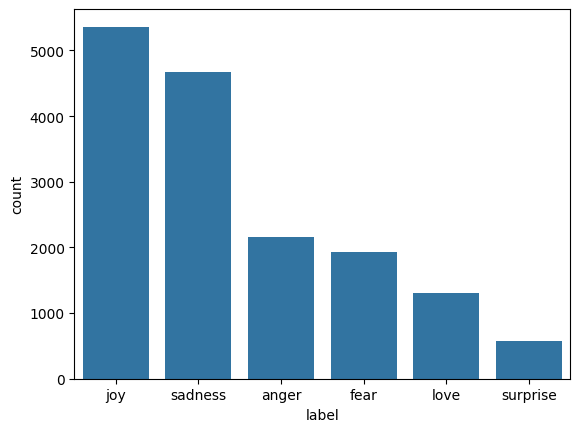

In [6]:
# plot count plot
sns.countplot(x='label', data=df_train, order = df_train['label'].value_counts().index)
plt.show()

4. Data Preprocessing using NLP

 Tokenize text , pad sequence to max length 50 and convert labels to Numpy arrars


In [7]:
import numpy as np

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# 1. Maximum vocabulary size
max_words = 10000


# 2. Create tokenizer
tokenizer = Tokenizer(
    num_words=max_words,
    oov_token='<unk>'
)


# 3. Fit tokenizer on training data only
tokenizer.fit_on_texts(df_train['text'])


# 4. Convert text into numerical sequences
train_sequence = tokenizer.texts_to_sequences(
    df_train['text']
)

test_sequence = tokenizer.texts_to_sequences(
    df_test['text']
)


# 5. Apply padding and truncation
padded_train_sequence = pad_sequences(
    train_sequence,
    maxlen=50,
    padding='post',
    truncating='post'
)

padded_test_sequence = pad_sequences(
    test_sequence,
    maxlen=50,
    padding='post',
    truncating='post'
)


# 6. Convert labels into NumPy arrays
train_labels = np.array(train_label)
test_labels = np.array(test_label)


# 7. Count unique classes
num_classes = len(np.unique(train_labels))

print("Number of classes:", num_classes)


# 8. Check shapes
print("Training sequences shape:", padded_train_sequence.shape)
print("Testing sequences shape:", padded_test_sequence.shape)

print("Training labels shape:", train_labels.shape)
print("Testing labels shape:", test_labels.shape)

print("Vocabulary size:", len(tokenizer.word_index))

Number of classes: 6
Training sequences shape: (16000, 50)
Testing sequences shape: (16000, 50)
Training labels shape: (16000,)
Testing labels shape: (16000,)
Vocabulary size: 15213


5. Shared Training Utilities

Compute balanced class weights to handle dataset skew and setup early stopping

In [8]:
from sklearn.utils import class_weight
import numpy as np

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict = dict(
    enumerate(class_weights)
)

In [9]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

6. Phase 1 -- Plain FOundational Models

Train plain (non- bidirectional) Simple RNN, standard LSTM, and Standard GRU models

In [10]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dropout, Dense, LSTM,GRU

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [14]:
history = rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(
    padded_test_sequence,
    test_labels,
    verbose=0
)

print(f"RNN Accuracy: {rnn_accuracy * 100:.2f}%")
print(f"RNN Loss: {rnn_loss:.4f}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - accuracy: 0.1607 - loss: 1.9191 - val_accuracy: 0.1528 - val_loss: 1.7936
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1468 - loss: 1.8040 - val_accuracy: 0.2554 - val_loss: 1.7534
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1670 - loss: 1.7824 - val_accuracy: 0.1696 - val_loss: 1.7579
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1585 - loss: 1.7675 - val_accuracy: 0.1832 - val_loss: 1.7512
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1545 - loss: 1.7754 - val_accuracy: 0.1865 - val_loss: 1.7589
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.1537 - loss: 1.7577 - val_accuracy: 0.0903 - val_loss: 1.8051
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1409 - loss: 1.7533 - val_accuracy: 0.1336 - val_loss: 1.7537
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.
RNN Accuracy:

6.2 Model 2 - Standard LSTM

In [15]:
lstm_model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=128
    ),

    LSTM(units=128, return_sequences=True),
    Dropout(0.5),

    LSTM(units=64),
    Dropout(0.5),

    Dense(units=num_classes, activation='softmax')
])

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [17]:
history = lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    padded_test_sequence,
    test_labels,
    verbose=0
)

print(f"LSTM Accuracy: {lstm_accuracy * 100:.2f}%")
print(f"LSTM Loss: {lstm_loss:.4f}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.1787 - loss: 1.7903 - val_accuracy: 0.1566 - val_loss: 1.7806
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.1874 - loss: 1.7740 - val_accuracy: 0.1978 - val_loss: 1.7424
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.2482 - loss: 1.6674 - val_accuracy: 0.3053 - val_loss: 1.5972
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.4029 - loss: 1.3005 - val_accuracy: 0.5626 - val_loss: 1.1479
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.6096 - loss: 0.8752 - val_accuracy: 0.7119 - val_loss: 0.7055
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8012 - loss: 0.5906 - val_accuracy: 0.8917 - val_loss: 0.3950
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8898 - loss: 0.3642 - val_accuracy: 0.9227 - val_loss: 0.2773
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9212 - loss: 0.2611 - val_acc

6.3 Model 3 - Standard GRU

In [18]:

gru_model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=128
    ),

    GRU(units=128, return_sequences=True),
    Dropout(0.5),

    GRU(units=64),
    Dropout(0.5),

    Dense(units=num_classes, activation='softmax')
])

gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [19]:
gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(
    padded_test_sequence,
    test_labels,
    verbose=0
)

print(f"GRU Accuracy: {gru_accuracy * 100:.2f}%")
print(f"GRU Loss: {gru_loss:.4f}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.1506 - loss: 1.7965 - val_accuracy: 0.3374 - val_loss: 1.7372
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1472 - loss: 1.7955 - val_accuracy: 0.3377 - val_loss: 1.7802
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1499 - loss: 1.7950 - val_accuracy: 0.2982 - val_loss: 1.7643
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
GRU Accuracy: 33.74%
GRU Loss: 1.7372


6.4 Phase 1 Ranking & selection

In [20]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Accuracy' : [rnn_accuracy, lstm_accuracy, gru_accuracy],
    'Test Loss' : [rnn_loss, lstm_loss, gru_loss]
}).sort_values(by='Test Accuracy', ascending=False)
result_df



,Model,Test Accuracy,Test Loss
1,LSTM,0.987938,0.039528
2,GRU,0.337375,1.737195
0,RNN,0.183187,1.751153


7 Phase 2 - Advance Bidirectional GRU

Enhance GRU with Bidirecional layers , 300D embeddings and 0.5 dropout regularization

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, GRU, Dropout, Dense, Bidirectional
)

bigru_model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=300
    ),

    Bidirectional(
        GRU(units=128, return_sequences=True)
    ),
    Dropout(0.5),

    Bidirectional(
        GRU(units=64)
    ),
    Dropout(0.5),

    Dense(
        units=num_classes,
        activation="softmax"
    )
])

bigru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bigru_model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [22]:
bigru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(
        padded_test_sequence,
        test_labels
    ),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
bigru_loss, bigru_accuracy = bigru_model.evaluate(
    padded_test_sequence,
    test_labels,
    verbose=0
)

print(f"BiGRU Accuracy: {bigru_accuracy * 100:.2f}%")
print(f"BiGRU Loss: {bigru_loss:.4f}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.5689 - loss: 1.0348 - val_accuracy: 0.9139 - val_loss: 0.2674
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9154 - loss: 0.2448 - val_accuracy: 0.9484 - val_loss: 0.1197
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9427 - loss: 0.1560 - val_accuracy: 0.9567 - val_loss: 0.1202
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
BiGRU Accuracy: 91.39%
BiGRU Loss: 0.2674


final model confuion matrix

500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step


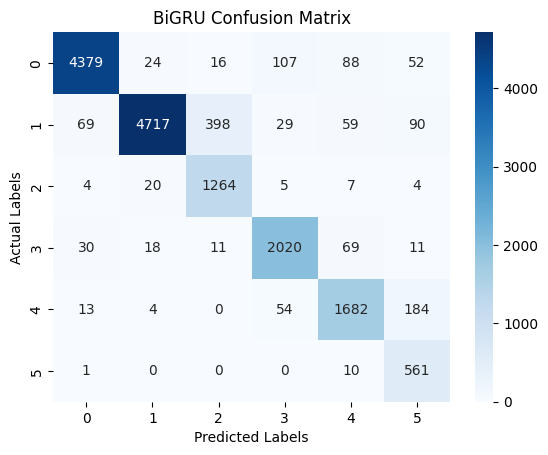

In [23]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate predictions
bigru_predictions = bigru_model.predict(padded_test_sequence)

# Convert probabilities into class labels
bigru_predictions = np.argmax(bigru_predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(test_labels, bigru_predictions)

# Plot heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('BiGRU Confusion Matrix')
plt.show()


final prediction

In [24]:

sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)

sample_padded_sequences = pad_sequences(
    sample_sequences,
    maxlen=50,
    padding='post',
    truncating='post'
)

sample_predictions = np.argmax(
    bigru_model.predict(sample_padded_sequences),
    axis=1
)

for i in range(len(sample_texts)):
    print(
        f"Text: {sample_texts[i]}\n"
        f"Predicted Emotion: {label_names[sample_predictions[i]]}\n"
    )


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise

Text: I feel so alone and hopeless today.
Predicted Emotion: sadness

Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger

Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise



Sava the model and tokenizer

In [25]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

# Save the bigru model
bigru_model.save(os.path.join(model_dir, 'bigru_model.keras'))

# Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as f:
    pickle.dump(tokenizer, f)
